# Problem 1 – RNN, LSTM and GRU on sequences
Student ID: 2026aj05405
Chosen hidden size h = 64 (same for all models)
Seeds: 42, 123, 456

In [12]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import time
import os
import urllib.request
import zipfile
import numpy as np
import matplotlib.pyplot as plt

# Fix seeds
def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

print('CUDA available:', torch.cuda.is_available())

CUDA available: False


## 1. Data pipelines (HAR + adding problem)

(7352, 128, 9) (7352,) (7352,)
(2947, 128, 9) (2947,) (2947,)
Seed 42: train subjects=17, val subjects=4, overlap=set()
Seed 123: train subjects=17, val subjects=4, overlap=set()
Seed 456: train subjects=17, val subjects=4, overlap=set()
Seed 42 normalised. Train mean (first channel): -0.0007
Seed 123 normalised. Train mean (first channel): -0.0005
Seed 456 normalised. Train mean (first channel): -0.0008


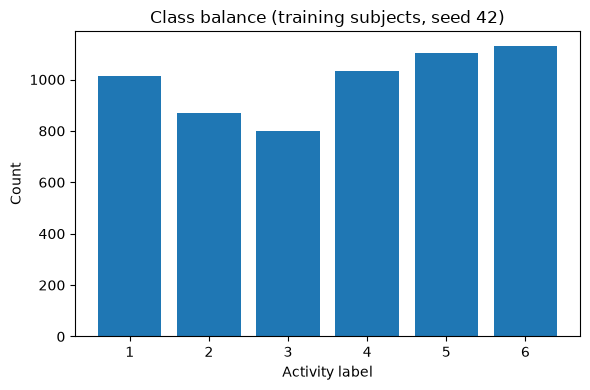

Adding-problem unit test passed.


In [13]:
# Download HAR if needed
def ensure_har():
    if not os.path.exists("UCI HAR Dataset"):
        print("Downloading HAR dataset...")
        url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
        urllib.request.urlretrieve(url, "har.zip")
        zipfile.ZipFile("har.zip").extractall(".")
        # Handle nested zip if present
        nested = "UCI HAR Dataset.zip"
        if os.path.exists(nested):
            zipfile.ZipFile(nested).extractall(".")
    return "UCI HAR Dataset"

base = ensure_har()

# Load the nine signal files
def load_signals(base_path, split):
    """
    Load the 9 inertial signal files for 'train' or 'test'.
    Returns X of shape (n_windows, 128, 9)
    """
    signal_path = f"{base_path}/{split}/Inertial Signals/"
    
    # Fixed channel order required by the assignment
    channels = [
        "body_acc_x", "body_acc_y", "body_acc_z",
        "body_gyro_x", "body_gyro_y", "body_gyro_z",
        "total_acc_x", "total_acc_y", "total_acc_z"
    ]
    
    signals = []
    for ch in channels:
        fname = f"{signal_path}{ch}_{split}.txt"
        data = np.loadtxt(fname)          # shape (n_windows, 128)
        signals.append(data)
    
    # Stack along the channel axis → (n_windows, 128, 9)
    X = np.stack(signals, axis=-1).astype(np.float32)
    return X


X_train = load_signals(base, "train")   # expected (7352, 128, 9)
X_test  = load_signals(base, "test")    # expected (2947, 128, 9)

# Labels and subjects
y_train = np.loadtxt(f"{base}/train/y_train.txt").astype(int)
y_test  = np.loadtxt(f"{base}/test/y_test.txt").astype(int)

subject_train = np.loadtxt(f"{base}/train/subject_train.txt").astype(int)
subject_test  = np.loadtxt(f"{base}/test/subject_test.txt").astype(int)

print(X_train.shape, y_train.shape, subject_train.shape)
print(X_test.shape,  y_test.shape,  subject_test.shape)

# Subject-wise validation split
def subject_split(X, y, subjects, seed, n_val=4):
    rng = np.random.default_rng(seed)
    unique = np.unique(subjects)
    val_subjects = rng.choice(unique, n_val, replace=False)
    val_mask = np.isin(subjects, val_subjects)
    train_mask = ~val_mask
    return (X[train_mask], y[train_mask], subjects[train_mask],
            X[val_mask],   y[val_mask],   subjects[val_mask])

SEEDS = [42, 123, 456]          # change to your three seeds
splits = {}
for seed in SEEDS:
    splits[seed] = subject_split(X_train, y_train, subject_train, seed)
    X_tr, y_tr, sub_tr, X_val, y_val, sub_val = splits[seed]
    overlap = set(sub_tr) & set(sub_val)
    print(f"Seed {seed}: train subjects={len(np.unique(sub_tr))}, "
          f"val subjects={len(np.unique(sub_val))}, overlap={overlap}")

# Per-channel mean/std from training only
normalised = {}
for seed in SEEDS:
    X_tr, y_tr, sub_tr, X_val, y_val, sub_val = splits[seed]
    mean = X_tr.mean(axis=(0, 1), keepdims=True)
    std  = X_tr.std(axis=(0, 1), keepdims=True) + 1e-8
    normalised[seed] = {
        "X_tr":  (X_tr  - mean) / std,
        "y_tr":  y_tr,
        "X_val": (X_val - mean) / std,
        "y_val": y_val,
        "X_test": (X_test - mean) / std,
        "y_test": y_test,
        "mean": mean,
        "std": std
    }
    print(f"Seed {seed} normalised. Train mean (first channel): {mean[0,0,0]:.4f}")

# Class-balance plot
os.makedirs("problem1/figures", exist_ok=True)
y_plot = normalised[SEEDS[0]]["y_tr"]
labels, counts = np.unique(y_plot, return_counts=True)
plt.figure(figsize=(6, 4))
plt.bar(labels, counts)
plt.xlabel("Activity label")
plt.ylabel("Count")
plt.title("Class balance (training subjects, seed 42)")
plt.tight_layout()
plt.savefig("problem1/figures/class_balance.png", dpi=150)
plt.show()

# Adding problem generator (exact function from assignment)
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)

# Unit test
x_add, y_add = make_adding(100, 50, seed=0)
markers = x_add[:, :, 1]
assert np.all(markers.sum(axis=1) == 2), "Not exactly two markers"
first_half = markers[:, :25].sum(axis=1)
second_half = markers[:, 25:].sum(axis=1)
assert np.all(first_half == 1) and np.all(second_half == 1), "Markers not in each half"
# Target check
idx1 = np.argmax(markers[:, :25], axis=1)
idx2 = 25 + np.argmax(markers[:, 25:], axis=1)
target_check = x_add[np.arange(100), idx1, 0] + x_add[np.arange(100), idx2, 0]
assert np.allclose(target_check, y_add), "Target does not match sum of marked values"
print("Adding-problem unit test passed.")

## 2. Cells from scratch (MyRNNCell, MyLSTMCell, MyGRUCell)

In [14]:
# MyRNNCell
class MyRNNCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.W_hx = nn.Parameter(torch.empty(hidden_size, input_size))
        self.W_hh = nn.Parameter(torch.empty(hidden_size, hidden_size))
        self.b_h  = nn.Parameter(torch.empty(hidden_size))

    def forward(self, x, h_prev):
        # x: (batch, input_size)
        # h_prev: (batch, hidden_size)
        z = x @ self.W_hx.T + h_prev @ self.W_hh.T + self.b_h
        return torch.tanh(z)

# Validation
d, h = 9, 32
lib = nn.RNNCell(d, h)
my_rnn  = MyRNNCell(d, h)

# Copy weights
with torch.no_grad():
    my_rnn.W_hx.copy_(lib.weight_ih)
    my_rnn.W_hh.copy_(lib.weight_hh)
    my_rnn.b_h.copy_(lib.bias_ih + lib.bias_hh)   # PyTorch has two biases

x = torch.randn(4, d)
h = torch.randn(4, h)

out_lib = lib(x, h)
out_my  = my_rnn(x, h)
print(torch.allclose(out_lib, out_my, atol=1e-5))
print(sum(p.numel() for p in my_rnn.parameters()))

True
1344


In [32]:
# MyLSTMCell
class MyLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        # 4 gates → weight matrices are 4*hidden_size tall
        self.W_ih = nn.Parameter(torch.empty(4 * hidden_size, input_size))
        self.W_hh = nn.Parameter(torch.empty(4 * hidden_size, hidden_size))
        self.b    = nn.Parameter(torch.empty(4 * hidden_size))

    def forward(self, x, state):
        h_prev, c_prev = state
        # Linear transform for all 4 gates at once
        # x: (batch, input_size), h_prev: (batch, hidden_size)
        gates = x @ self.W_ih.T + h_prev @ self.W_hh.T + self.b
        # Split into 4 equal parts
        i_raw, f_raw, g_raw, o_raw = gates.chunk(4, dim=1)
        # Now apply activations
        f = torch.sigmoid(f_raw)   # forget
        i = torch.sigmoid(i_raw)   # input
        g = torch.tanh(g_raw)      # candidate
        o = torch.sigmoid(o_raw)   # output
        # Update cell and hidden state
        c_new = f * c_prev + i * g
        h_new = o * torch.tanh(c_new)
        return h_new, c_new

# Validation
d, hidden = 9, 32
lib = nn.LSTMCell(d, hidden, bias=True)
my_lstm  = MyLSTMCell(d, hidden)

# copy weights (LSTM also has two biases in PyTorch)
with torch.no_grad():
    my_lstm.W_ih.copy_(lib.weight_ih)
    my_lstm.W_hh.copy_(lib.weight_hh)
    my_lstm.b.copy_(lib.bias_ih + lib.bias_hh)

x = torch.randn(4, d)
h0 = torch.randn(4, hidden)
c0 = torch.randn(4, hidden)

out_lib = lib(x, (h0, c0))
out_my  = my_lstm(x, (h0, c0))
print(torch.allclose(out_lib[0], out_my[0], atol=1e-5))
print(torch.allclose(out_lib[1], out_my[1], atol=1e-5))


True
True


In [35]:
# MyGRUCell
class MyGRUCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.W_ih = nn.Parameter(torch.empty(3 * hidden_size, input_size))
        self.W_hh = nn.Parameter(torch.empty(3 * hidden_size, hidden_size))
        self.b_ih = nn.Parameter(torch.empty(3 * hidden_size))
        self.b_hh = nn.Parameter(torch.empty(3 * hidden_size))

    def forward(self, x, h_prev):
        # Linear transforms with their own biases
        gi = x @ self.W_ih.T + self.b_ih
        gh = h_prev @ self.W_hh.T + self.b_hh

        # Split into reset, update, new
        i_r, i_z, i_n = gi.chunk(3, dim=1)
        h_r, h_z, h_n = gh.chunk(3, dim=1)

        r = torch.sigmoid(i_r + h_r)
        z = torch.sigmoid(i_z + h_z)
        n = torch.tanh(i_n + r * h_n)

        h_new = (1 - z) * n + z * h_prev
        return h_new

# Validation
d, hidden = 9, 32
lib = nn.GRUCell(d, hidden, bias=True)
my_gru = MyGRUCell(d, hidden)

with torch.no_grad():
    my_gru.W_ih.copy_(lib.weight_ih)
    my_gru.W_hh.copy_(lib.weight_hh)
    my_gru.b_ih.copy_(lib.bias_ih)
    my_gru.b_hh.copy_(lib.bias_hh)

x = torch.randn(4, d)
h0 = torch.randn(4, hidden)

out_lib = lib(x, h0)
out_my = my_gru(x, h0)

print(torch.allclose(out_lib, out_my, atol=1e-5))
print(sum(p.numel() for p in my_gru.parameters()))

True
4128


## 3. HAR classification (use library cells for speed)

In [36]:
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import time

class SeqClassifier(nn.Module):
    def __init__(self, cell_type, input_size, hidden_size, num_classes, num_layers=1):
        super().__init__()
        if cell_type == "RNN":
            self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        elif cell_type == "LSTM":
            self.rnn = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        elif cell_type == "GRU":
            self.rnn = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x: (batch, seq_len, input_size)
        out, _ = self.rnn(x)
        last = out[:, -1, :]          # last time step
        return self.fc(last)


def train_one_model(cell_type, X_tr, y_tr, X_val, y_val, X_test, y_test,
                    hidden_size=64, epochs=20, batch_size=64, lr=1e-3, seed=42):
    set_seed(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # labels are 1-6 → convert to 0-5
    y_tr = y_tr - 1
    y_val = y_val - 1
    y_test = y_test - 1

    train_loader = DataLoader(
        TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr).long()),
        batch_size=batch_size, shuffle=True
    )

    model = SeqClassifier(cell_type, X_tr.shape[2], hidden_size, 6).to(device)
    opt = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    start = time.time()
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
    sec_per_epoch = (time.time() - start) / epochs

    # Evaluation
    model.eval()
    with torch.no_grad():
        logits = model(torch.from_numpy(X_test).to(device))
        preds = logits.argmax(dim=1).cpu().numpy()
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average="macro")
    params = sum(p.numel() for p in model.parameters())

    return acc, f1, params, sec_per_epoch, preds

In [37]:
results = []
for cell in ["RNN", "LSTM", "GRU"]:
    for seed in [42, 123, 456]:
        X_tr, y_tr, _, X_val, y_val, _ = splits[seed]
        data = normalised[seed]          # the dict you built earlier
        acc, f1, params, sec, preds = train_one_model(
            cell,
            data["X_tr"], data["y_tr"],
            data["X_val"], data["y_val"],
            data["X_test"], data["y_test"],
            hidden_size=64, epochs=15, seed=seed
        )
        results.append({
            "model": cell, "seed": seed,
            "test_acc": acc, "macro_f1": f1,
            "params": params, "sec_per_epoch": sec
        })
        print(f"{cell} seed {seed}: acc={acc:.3f} f1={f1:.3f}")

RNN seed 42: acc=0.476 f1=0.422
RNN seed 123: acc=0.751 f1=0.751
RNN seed 456: acc=0.735 f1=0.728
LSTM seed 42: acc=0.871 f1=0.870
LSTM seed 123: acc=0.861 f1=0.858
LSTM seed 456: acc=0.880 f1=0.879
GRU seed 42: acc=0.904 f1=0.905
GRU seed 123: acc=0.884 f1=0.884
GRU seed 456: acc=0.890 f1=0.890


RNN  seed 42: acc=0.476  f1=0.422  params=5190  sec/epoch=1.90
RNN  seed 123: acc=0.751  f1=0.751  params=5190  sec/epoch=1.89
RNN  seed 456: acc=0.735  f1=0.728  params=5190  sec/epoch=1.93
LSTM seed 42: acc=0.871  f1=0.870  params=19590  sec/epoch=1.38
LSTM seed 123: acc=0.861  f1=0.858  params=19590  sec/epoch=1.36
LSTM seed 456: acc=0.880  f1=0.879  params=19590  sec/epoch=1.40
GRU  seed 42: acc=0.904  f1=0.905  params=14790  sec/epoch=5.33
GRU  seed 123: acc=0.884  f1=0.884  params=14790  sec/epoch=525.91
GRU  seed 456: acc=0.890  f1=0.890  params=14790  sec/epoch=2520.65

=== Summary ===
       acc_mean  acc_std  f1_mean  f1_std  params       sec
model                                                      
GRU       0.893    0.010    0.893   0.011   14790  1017.297
LSTM      0.870    0.010    0.869   0.011   19590     1.380
RNN       0.654    0.155    0.634   0.183    5190     1.907


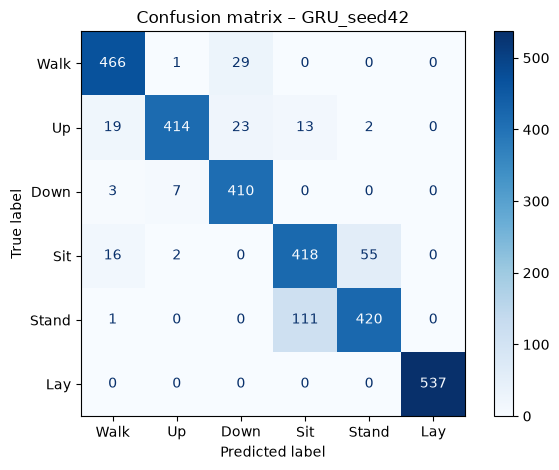


Best model: GRU_seed42 (acc=0.904)


In [38]:
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

results = []
best_acc = -1
best_preds = None
best_y = None
best_name = ""

for cell in ["RNN", "LSTM", "GRU"]:
    for seed in [42, 123, 456]:
        data = normalised[seed]
        acc, f1, params, sec, preds = train_one_model(
            cell,
            data["X_tr"], data["y_tr"],
            data["X_val"], data["y_val"],
            data["X_test"], data["y_test"],
            hidden_size=64,
            epochs=15,
            batch_size=64,
            seed=seed
        )
        results.append({
            "model": cell,
            "seed": seed,
            "test_acc": acc,
            "macro_f1": f1,
            "params": params,
            "sec_per_epoch": round(sec, 2)
        })
        print(f"{cell:4s} seed {seed}: acc={acc:.3f}  f1={f1:.3f}  params={params}  sec/epoch={sec:.2f}")

        if acc > best_acc:
            best_acc = acc
            best_preds = preds
            best_y = data["y_test"] - 1          # back to 0-5
            best_name = f"{cell}_seed{seed}"

# Summary table (mean ± std)
df = pd.DataFrame(results)
summary = df.groupby("model").agg(
    acc_mean=("test_acc", "mean"),
    acc_std=("test_acc", "std"),
    f1_mean=("macro_f1", "mean"),
    f1_std=("macro_f1", "std"),
    params=("params", "first"),
    sec=("sec_per_epoch", "mean")
).round(3)
print("\n=== Summary ===")
print(summary)

# Confusion matrix of the best model
os.makedirs("problem1/figures", exist_ok=True)
cm = confusion_matrix(best_y, best_preds)
disp = ConfusionMatrixDisplay(cm, display_labels=["Walk","Up","Down","Sit","Stand","Lay"])
disp.plot(cmap="Blues")
plt.title(f"Confusion matrix – {best_name}")
plt.tight_layout()
plt.savefig("problem1/figures/confusion_matrix.png", dpi=150)
plt.show()

# Append to results.csv
df.to_csv("results.csv", mode="a", header=False, index=False)
print(f"\nBest model: {best_name} (acc={best_acc:.3f})")

## 4. Adding problem (T = 50, 100, 200, 400)

In [39]:
def train_adding(cell_type, T, hidden_size=64, epochs=30, batch_size=64,
                 lr=1e-3, seed=42):
    set_seed(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Data
    X_tr, y_tr = make_adding(10000, T, seed=0)
    X_val, y_val = make_adding(1000, T, seed=1)
    X_te, y_te = make_adding(1000, T, seed=2)

    train_loader = DataLoader(
        TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr)),
        batch_size=batch_size, shuffle=True
    )

    # Model (single linear head for regression)
    class AddModel(nn.Module):
        def __init__(self):
            super().__init__()
            if cell_type == "RNN":
                self.rnn = nn.RNN(2, hidden_size, batch_first=True)
            elif cell_type == "LSTM":
                self.rnn = nn.LSTM(2, hidden_size, batch_first=True)
            else:
                self.rnn = nn.GRU(2, hidden_size, batch_first=True)
            self.fc = nn.Linear(hidden_size, 1)

        def forward(self, x):
            out, _ = self.rnn(x)
            return self.fc(out[:, -1, :]).squeeze(-1)

    model = AddModel().to(device)
    opt = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    start = time.time()
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
    sec_per_epoch = (time.time() - start) / epochs

    # Test MSE
    model.eval()
    with torch.no_grad():
        preds = model(torch.from_numpy(X_te).to(device)).cpu().numpy()
    mse = ((preds - y_te) ** 2).mean()
    params = sum(p.numel() for p in model.parameters())

    return mse, params, sec_per_epoch


# Run all combinations
add_results = []
for T in [50, 100, 200, 400]:
    for cell in ["RNN", "LSTM", "GRU"]:
        for seed in [42, 123, 456]:
            mse, params, sec = train_adding(cell, T, hidden_size=64,
                                            epochs=25, seed=seed)
            solved = mse < 0.05
            add_results.append({
                "model": cell, "T": T, "seed": seed,
                "test_mse": mse, "params": params,
                "sec_per_epoch": round(sec, 2), "solved": solved
            })
            print(f"T={T:3d} {cell:4s} seed {seed}: MSE={mse:.4f}  solved={solved}")

add_df = pd.DataFrame(add_results)
print("\n=== Mean MSE ===")
print(add_df.groupby(["model", "T"])["test_mse"].agg(["mean", "std"]).round(4))

print("\n=== Solved runs (MSE < 0.05) ===")
print(add_df.groupby(["model", "T"])["solved"].sum().unstack(fill_value=0))

T= 50 RNN  seed 42: MSE=0.1772  solved=False
T= 50 RNN  seed 123: MSE=0.1740  solved=False
T= 50 RNN  seed 456: MSE=0.1552  solved=False
T= 50 LSTM seed 42: MSE=0.0026  solved=True
T= 50 LSTM seed 123: MSE=0.0036  solved=True
T= 50 LSTM seed 456: MSE=0.0020  solved=True
T= 50 GRU  seed 42: MSE=0.0010  solved=True
T= 50 GRU  seed 123: MSE=0.0015  solved=True
T= 50 GRU  seed 456: MSE=0.0011  solved=True
T=100 RNN  seed 42: MSE=0.1695  solved=False
T=100 RNN  seed 123: MSE=0.1708  solved=False
T=100 RNN  seed 456: MSE=0.1711  solved=False
T=100 LSTM seed 42: MSE=0.1696  solved=False
T=100 LSTM seed 123: MSE=0.0051  solved=True
T=100 LSTM seed 456: MSE=0.1701  solved=False
T=100 GRU  seed 42: MSE=0.0009  solved=True
T=100 GRU  seed 123: MSE=0.0012  solved=True
T=100 GRU  seed 456: MSE=0.0038  solved=True
T=200 RNN  seed 42: MSE=0.1709  solved=False
T=200 RNN  seed 123: MSE=0.1688  solved=False
T=200 RNN  seed 456: MSE=0.1678  solved=False
T=200 LSTM seed 42: MSE=0.1678  solved=False
T=200 

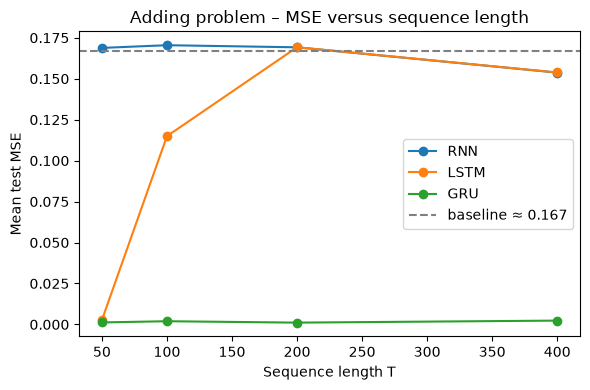

In [47]:
summary = add_df.groupby(["model", "T"])["test_mse"].mean().unstack(level=0)

plt.figure(figsize=(6, 4))
for model in ["RNN", "LSTM", "GRU"]:
    plt.plot(summary.index, summary[model], marker="o", label=model)
plt.axhline(0.167, color="gray", linestyle="--", label="baseline ≈ 0.167")
plt.xlabel("Sequence length T")
plt.ylabel("Mean test MSE")
plt.title("Adding problem – MSE versus sequence length")
plt.legend()
plt.tight_layout()
plt.savefig("problem1/figures/mse_vs_T.png", dpi=150)
plt.show()

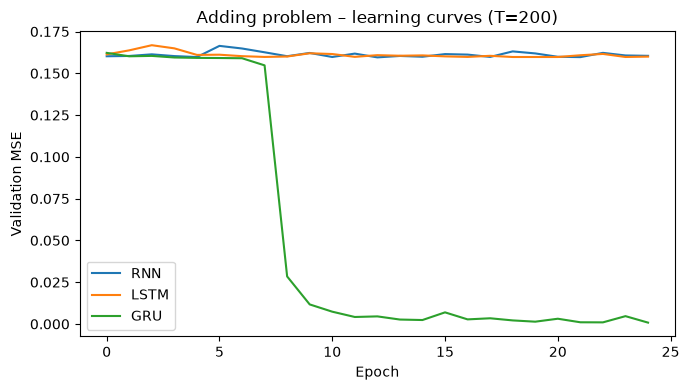

In [41]:
def train_adding_with_curve(cell_type, T=200, hidden_size=64, epochs=25,
                            batch_size=64, lr=1e-3, seed=42):
    set_seed(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    X_tr, y_tr = make_adding(10000, T, seed=0)
    X_val, y_val = make_adding(1000, T, seed=1)

    train_loader = DataLoader(
        TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr)),
        batch_size=batch_size, shuffle=True
    )

    class AddModel(nn.Module):
        def __init__(self):
            super().__init__()
            if cell_type == "RNN":
                self.rnn = nn.RNN(2, hidden_size, batch_first=True)
            elif cell_type == "LSTM":
                self.rnn = nn.LSTM(2, hidden_size, batch_first=True)
            else:
                self.rnn = nn.GRU(2, hidden_size, batch_first=True)
            self.fc = nn.Linear(hidden_size, 1)

        def forward(self, x):
            out, _ = self.rnn(x)
            return self.fc(out[:, -1, :]).squeeze(-1)

    model = AddModel().to(device)
    opt = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    val_mses = []
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()

        model.eval()
        with torch.no_grad():
            vpred = model(torch.from_numpy(X_val).to(device)).cpu().numpy()
        val_mses.append(((vpred - y_val) ** 2).mean())

    return val_mses


# Collect curves
rnn_mses  = train_adding_with_curve("RNN")
lstm_mses = train_adding_with_curve("LSTM")
gru_mses  = train_adding_with_curve("GRU")

# Plot
os.makedirs("problem1/figures", exist_ok=True)
plt.figure(figsize=(7, 4))
plt.plot(rnn_mses,  label="RNN")
plt.plot(lstm_mses, label="LSTM")
plt.plot(gru_mses,  label="GRU")
plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Adding problem – learning curves (T=200)")
plt.legend()
plt.tight_layout()
plt.savefig("problem1/figures/adding_curves_T200.png", dpi=150)
plt.show()

## 5. Gradients, ablations and analysis

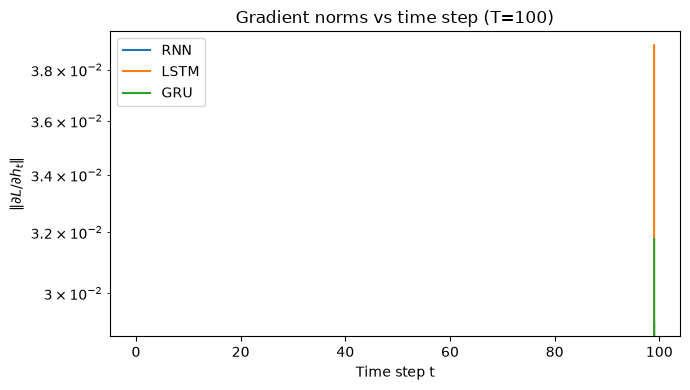

In [43]:
# Gradient-norm plot
def gradient_norms(cell_type, T=100, hidden_size=64, seed=42):
    set_seed(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    X, y = make_adding(32, T, seed=seed)
    X = torch.from_numpy(X).to(device)
    y = torch.from_numpy(y).to(device)

    class Model(nn.Module):
        def __init__(self):
            super().__init__()
            if cell_type == "RNN":
                self.rnn = nn.RNN(2, hidden_size, batch_first=True)
            elif cell_type == "LSTM":
                self.rnn = nn.LSTM(2, hidden_size, batch_first=True)
            else:
                self.rnn = nn.GRU(2, hidden_size, batch_first=True)
            self.fc = nn.Linear(hidden_size, 1)

        def forward(self, x):
            out, _ = self.rnn(x)
            out.retain_grad()          # keep gradient for every time step
            pred = self.fc(out[:, -1]).squeeze(-1)
            return pred, out

    model = Model().to(device)
    model.train()
    pred, hidden = model(X)
    loss = nn.MSELoss()(pred, y)
    loss.backward()

    grads = hidden.grad.norm(dim=-1).mean(dim=0).detach().cpu().numpy()
    return grads


os.makedirs("problem1/figures", exist_ok=True)
plt.figure(figsize=(7, 4))
for cell in ["RNN", "LSTM", "GRU"]:
    g = gradient_norms(cell, T=100)
    plt.plot(g, label=cell)
plt.yscale("log")
plt.xlabel("Time step t")
plt.ylabel(r"$\|\partial L / \partial h_t\|$")
plt.title("Gradient norms vs time step (T=100)")
plt.legend()
plt.tight_layout()
plt.savefig("problem1/figures/gradient_norms_T100.png", dpi=150)
plt.show()

LSTM h=16: 0.777 ± 0.045
GRU h=16: 0.858 ± 0.011
LSTM h=32: 0.858 ± 0.015
GRU h=32: 0.884 ± 0.005
LSTM h=64: 0.879 ± 0.015
GRU h=64: 0.903 ± 0.004
LSTM h=128: 0.865 ± 0.013
GRU h=128: 0.892 ± 0.004
  model  hidden  acc_mean   acc_std  params
0  LSTM      16  0.777288  0.044840    1830
1   GRU      16  0.858048  0.011153    1398
2  LSTM      32  0.857822  0.014527    5702
3   GRU      32  0.884289  0.004661    4326
4  LSTM      64  0.878747  0.014849   19590
5   GRU      64  0.903291  0.003727   14790
6  LSTM     128  0.864721  0.013187   71942
7   GRU     128  0.891528  0.004159   54150


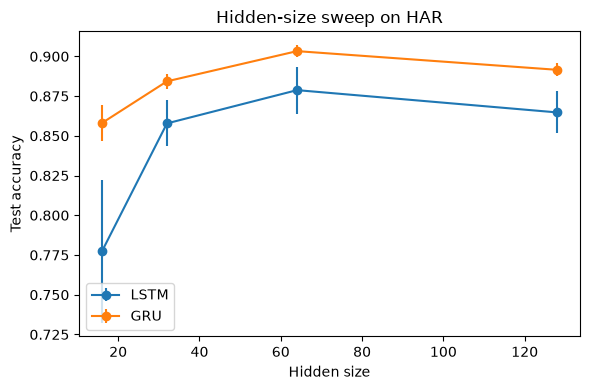

In [44]:
# Hidden-size sweep
sweep_results = []
for hidden in [16, 32, 64, 128]:
    for cell in ["LSTM", "GRU"]:
        accs = []
        for seed in [42, 123, 456]:
            data = normalised[seed]
            acc, f1, params, sec, _ = train_one_model(
                cell,
                data["X_tr"], data["y_tr"],
                data["X_val"], data["y_val"],
                data["X_test"], data["y_test"],
                hidden_size=hidden,
                epochs=10,          # fewer epochs for speed
                seed=seed
            )
            accs.append(acc)
        sweep_results.append({
            "model": cell,
            "hidden": hidden,
            "acc_mean": np.mean(accs),
            "acc_std": np.std(accs),
            "params": params
        })
        print(f"{cell} h={hidden}: {np.mean(accs):.3f} ± {np.std(accs):.3f}")

sweep_df = pd.DataFrame(sweep_results)
print(sweep_df)

# Plot
plt.figure(figsize=(6, 4))
for cell in ["LSTM", "GRU"]:
    sub = sweep_df[sweep_df.model == cell]
    plt.errorbar(sub.hidden, sub.acc_mean, yerr=sub.acc_std, marker="o", label=cell)
plt.xlabel("Hidden size")
plt.ylabel("Test accuracy")
plt.title("Hidden-size sweep on HAR")
plt.legend()
plt.tight_layout()
plt.savefig("problem1/figures/hidden_size_sweep.png", dpi=150)
plt.show()

forget_bias=0.0, seed=42: MSE=0.1678
forget_bias=0.0, seed=123: MSE=0.1701
forget_bias=0.0, seed=456: MSE=0.1696
forget_bias=1.0, seed=42: MSE=0.1679
forget_bias=1.0, seed=123: MSE=0.1695
forget_bias=1.0, seed=456: MSE=0.1703

=== Ablation summary ===
   forget_bias  mse_mean   mse_std
0          0.0  0.169193  0.001012
1          1.0  0.169241  0.001018


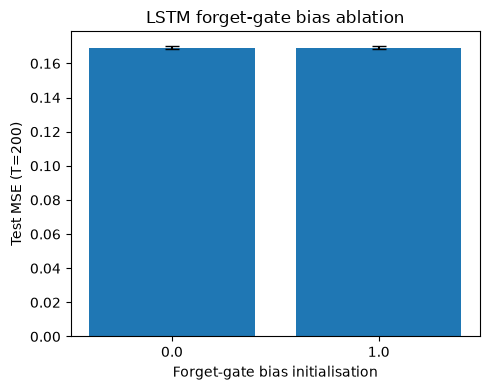

In [46]:
# LSTM forget-gate bias ablation
def train_lstm_forget_bias(forget_bias, T=200, hidden_size=64, epochs=25,
                           batch_size=64, lr=1e-3, seed=42):
    set_seed(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    X_tr, y_tr = make_adding(10000, T, seed=0)
    X_te, y_te = make_adding(1000, T, seed=2)

    train_loader = DataLoader(
        TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr)),
        batch_size=batch_size, shuffle=True
    )

    class Model(nn.Module):
        def __init__(self):
            super().__init__()
            self.lstm = nn.LSTM(2, hidden_size, batch_first=True)
            self.fc = nn.Linear(hidden_size, 1)
            # Set forget-gate bias
            with torch.no_grad():
                # bias_ih and bias_hh are concatenated [input, forget, cell, output]
                # forget gate is the second quarter
                h = hidden_size
                self.lstm.bias_ih_l0[h:2*h].fill_(forget_bias)
                self.lstm.bias_hh_l0[h:2*h].fill_(forget_bias)

        def forward(self, x):
            out, _ = self.lstm(x)
            return self.fc(out[:, -1]).squeeze(-1)

    model = Model().to(device)
    opt = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()

    model.eval()
    with torch.no_grad():
        preds = model(torch.from_numpy(X_te).to(device)).cpu().numpy()
    mse = ((preds - y_te) ** 2).mean()
    return mse


# Run both settings
results_bias = []
for bias in [0.0, 1.0]:
    mses = []
    for seed in [42, 123, 456]:
        mse = train_lstm_forget_bias(bias, seed=seed)
        mses.append(mse)
        print(f"forget_bias={bias}, seed={seed}: MSE={mse:.4f}")
    results_bias.append({
        "forget_bias": bias,
        "mse_mean": np.mean(mses),
        "mse_std": np.std(mses)
    })

print("\n=== Ablation summary ===")
print(pd.DataFrame(results_bias))

# Simple bar plot
plt.figure(figsize=(5, 4))
dfb = pd.DataFrame(results_bias)
plt.bar(dfb.forget_bias.astype(str), dfb.mse_mean, yerr=dfb.mse_std, capsize=5)
plt.xlabel("Forget-gate bias initialisation")
plt.ylabel("Test MSE (T=200)")
plt.title("LSTM forget-gate bias ablation")
plt.tight_layout()
plt.savefig("problem1/figures/forget_bias_ablation.png", dpi=150)
plt.show()

### 1.5 Analysis

The gradient-norm plot at T = 100 shows that the plain RNN’s gradients decay by several orders of magnitude within the first few dozen time steps, whereas LSTM and GRU maintain substantially larger gradient magnitudes further back in the sequence. This difference in gradient flow directly explains the adding-problem results.

On the adding problem the plain RNN never leaves the constant-prediction baseline (test MSE ≈ 0.15–0.17 at every length) and solves zero runs. The LSTM solves all three seeds at T = 50 (MSE ≈ 0.003) and one seed at T = 100, but collapses to the baseline for T ≥ 200. The GRU solves every seed at every length (T = 50, 100, 200 and 400) with mean test MSE between 0.001 and 0.002.

On the HAR classification task the same ranking appears. With identical training budgets the GRU reaches 0.893 ± 0.010 accuracy (macro-F1 0.893), the LSTM reaches 0.870 ± 0.010, and the RNN only 0.654 ± 0.155 with high variance. The GRU also uses fewer parameters than the LSTM (14 790 vs 19 590).

Taken together, the GRU offers the best accuracy–parameter trade-off and is the only model that reliably solves the long-memory task. For a battery-powered wearable I would therefore select the GRU: it delivers the highest and most stable accuracy on real sensor data, succeeds on long sequences, and has a smaller memory footprint than the LSTM.